# Retail Customer Sales — Data Visualization & Business Analysis
**Ready-to-run project notebook**

This notebook analyzes the cleaned retail transaction dataset and creates the visual report required by the project brief. It includes data loading, quality checks, KPIs, **11+ charts**, chart-by-chart business insights, and an overall conclusion.

**Dataset:** `retail_customer_sales_cleaned.csv`  
**Expected data:** 7,000 transaction rows and 24 columns.

> Keep this notebook and the CSV file in the same folder. Run the notebook from top to bottom.

## 1. Project objectives and chart checklist

The notebook covers:
1. Monthly sales trend (line chart)
2. Sales by region (bar chart)
3. Sales by product category (bar chart)
4. Age distribution (histogram)
5. Income distribution (histogram)
6. Sales distribution by product category (box plot)
7. Sales vs Profit (scatter plot + trend line)
8. Discount vs Profit (scatter plot + trend line)
9. Sales share by customer segment (donut chart)
10. Correlation heatmap
11. Average sales by product category and region (pivot heatmap)

Additional analysis includes customer satisfaction, returns, payment methods, delivery modes, profit margin, and key business recommendations.

In [4]:
pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [7]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [3]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 3. Load dataset

In [26]:
DATA_FILE = Path("retail_customer_sales_cleaned.csv")
if not DATA_FILE.exists():
    # Fallback for this prepared project environment
    DATA_FILE = Path("/mnt/data/retail_customer_sales_cleaned.csv")

df = pd.read_csv(DATA_FILE)
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Delivery_Date"] = pd.to_datetime(df["Delivery_Date"], errors="coerce")

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset loaded: 7,000 rows × 24 columns


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.00,Male,"62,828.52",West,Gujarat,Surat,Consumer,Grocery,Honey Jar,3,887.94,0.32,"1,811.40","1,204.47",606.93,Debit Card,Standard,3.00,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.00,Male,"50,952.64",North,Haryana,Gurugram,Home Office,Electronics,USB-C Hub,2,"14,309.96",0.18,"23,468.33","17,137.06","6,331.27",Credit Card,Standard,3.00,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.00,Male,"60,476.00",East,Jharkhand,Ranchi,Consumer,Clothing,Winter Jacket,4,710.95,0.09,"2,587.86","1,577.83","1,010.03",Debit Card,Express,3.00,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.00,Male,"41,516.94",West,Gujarat,Surat,Home Office,Grocery,Olive Oil 1L,4,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.00,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.00,Female,"95,727.49",North,Haryana,Gurugram,Consumer,Electronics,Laptop Stand,1,"10,542.13",0.21,"8,328.28","5,528.47","2,799.81",UPI,Express,1.00,Low,No


## 4. Data quality and preparation checks

In [27]:
print("Dataset dimensions:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

quality = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique()
}).sort_values("Missing %", ascending=False)
display(quality)

print("Duplicate full rows:", df.duplicated().sum())
print("Duplicate Transaction_ID values:", df["Transaction_ID"].duplicated().sum())
print("Date range:", df["Order_Date"].min().date(), "to", df["Order_Date"].max().date())

Dataset dimensions: (7000, 24)

Data types:


,Data Type
Transaction_ID,str
Customer_ID,str
Order_Date,datetime64[us]
Delivery_Date,datetime64[us]
Age,float64
Gender,str
Income,float64
Region,str
State,str
City,str


,Missing Values,Missing %,Unique Values
Customer_Rating,420,6.00,5
Income,245,3.50,1574
Satisfaction_Level,175,2.50,3
Delivery_Date,158,2.26,740
Age,146,2.09,50
Discount,76,1.09,51
Order_Date,0,0.00,731
Transaction_ID,0,0.00,7000
Region,0,0.00,4
Gender,0,0.00,2


Duplicate full rows: 0
Duplicate Transaction_ID values: 0
Date range: 2023-01-01 to 2024-12-31


### Preparation notes
The supplied cleaned file already has duplicate transaction records removed, text labels standardized, and date formats parsed. Invalid age, discount, rating, and delivery-date values were left blank rather than guessed. Missing values are retained; each analysis uses the available valid observations for its variables. Extreme income observations are retained for transparent outlier analysis.

## 5. KPI overview

In [28]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_cost = df["Cost"].sum()
total_quantity = df["Quantity"].sum()
transaction_count = df["Transaction_ID"].nunique()
customer_count = df["Customer_ID"].nunique()
profit_margin = (total_profit / total_sales * 100) if total_sales else np.nan
avg_order_value = total_sales / transaction_count if transaction_count else np.nan
avg_profit_per_order = total_profit / transaction_count if transaction_count else np.nan

kpis = pd.DataFrame({
    "KPI": ["Total Sales", "Total Profit", "Total Cost", "Profit Margin",
            "Average Order Value", "Average Profit per Transaction",
            "Transactions", "Unique Customers", "Units Sold"],
    "Value": [total_sales, total_profit, total_cost, profit_margin,
              avg_order_value, avg_profit_per_order,
              transaction_count, customer_count, total_quantity]
})
display(kpis)

,KPI,Value
0,Total Sales,"76,731,189.27"
1,Total Profit,"25,127,882.66"
2,Total Cost,"51,603,306.61"
3,Profit Margin,32.75
4,Average Order Value,"10,961.60"
5,Average Profit per Transaction,"3,589.70"
6,Transactions,"7,000.00"
7,Unique Customers,"1,576.00"
8,Units Sold,"21,068.00"


## 6. Chart 1 — Monthly sales trend

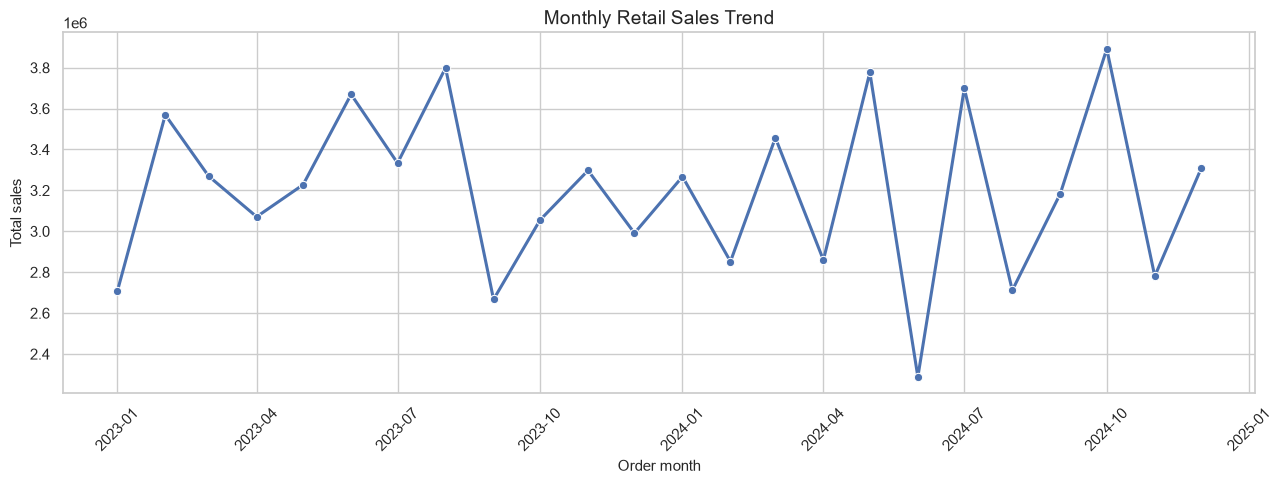

INSIGHT: Highest sales occurred in Oct 2024 (3,891,899.13); lowest sales occurred in Jun 2024 (2,288,000.37). Use this monthly pattern to plan inventory and promotions.


In [29]:
monthly_sales = (df.dropna(subset=["Order_Date"])
                   .assign(Month=lambda x: x["Order_Date"].dt.to_period("M").dt.to_timestamp())
                   .groupby("Month", as_index=False)["Sales"].sum())

fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=monthly_sales, x="Month", y="Sales", marker="o", linewidth=2.2, ax=ax)
ax.set(title="Monthly Retail Sales Trend", xlabel="Order month", ylabel="Total sales")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

if len(monthly_sales) > 0:
    peak = monthly_sales.loc[monthly_sales["Sales"].idxmax()]
    low = monthly_sales.loc[monthly_sales["Sales"].idxmin()]
    print(f"INSIGHT: Highest sales occurred in {peak['Month']:%b %Y} "
          f"({peak['Sales']:,.2f}); lowest sales occurred in {low['Month']:%b %Y} "
          f"({low['Sales']:,.2f}). Use this monthly pattern to plan inventory and promotions.")

## 7. Chart 2 — Total sales by region

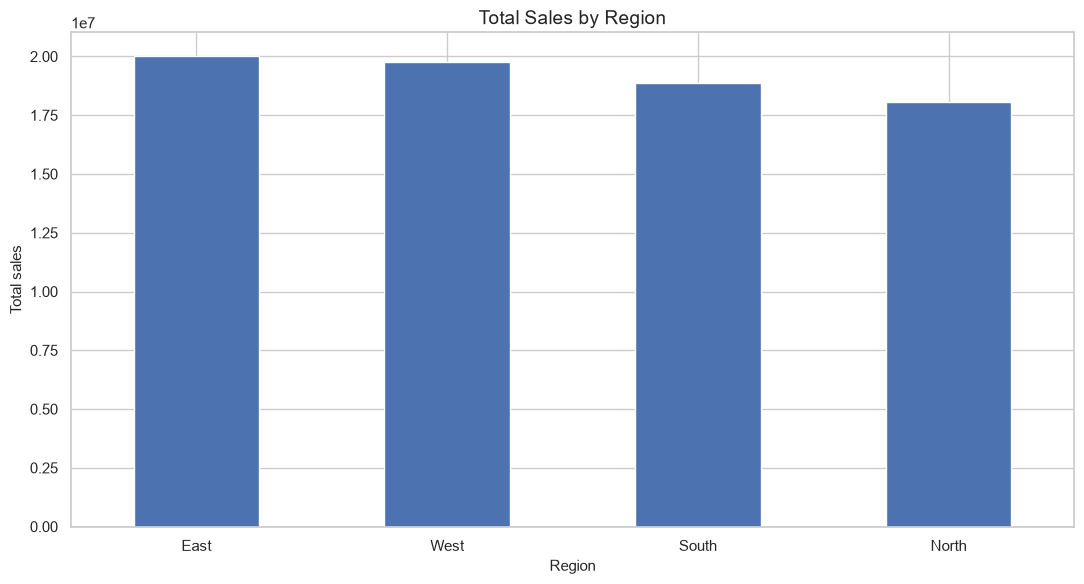

INSIGHT: East is the highest-sales region (20,018,192.35); North is the lowest (18,063,891.81). Regional teams can compare execution and demand.


In [30]:
region_sales = df.groupby("Region", dropna=False)["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots()
region_sales.plot(kind="bar", ax=ax)
ax.set(title="Total Sales by Region", xlabel="Region", ylabel="Total sales")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
print(f"INSIGHT: {region_sales.index[0]} is the highest-sales region "
      f"({region_sales.iloc[0]:,.2f}); {region_sales.index[-1]} is the lowest "
      f"({region_sales.iloc[-1]:,.2f}). Regional teams can compare execution and demand.")

## 8. Chart 3 — Total sales by product category

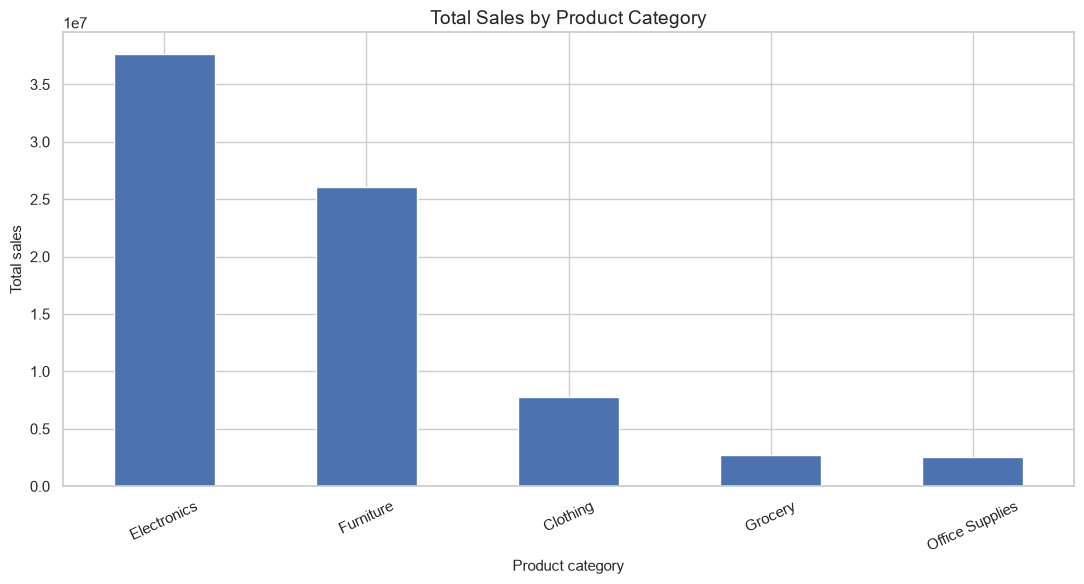

INSIGHT: Electronics contributes the most sales (37,639,557.39), while Office Supplies contributes the least. Use this ranking when reviewing category-level assortment and marketing investment.


In [31]:
category_sales = df.groupby("Product_Category")["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots()
category_sales.plot(kind="bar", ax=ax)
ax.set(title="Total Sales by Product Category", xlabel="Product category", ylabel="Total sales")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
print(f"INSIGHT: {category_sales.index[0]} contributes the most sales "
      f"({category_sales.iloc[0]:,.2f}), while {category_sales.index[-1]} contributes the least. "
      "Use this ranking when reviewing category-level assortment and marketing investment.")

## 9. Chart 4 — Customer age distribution

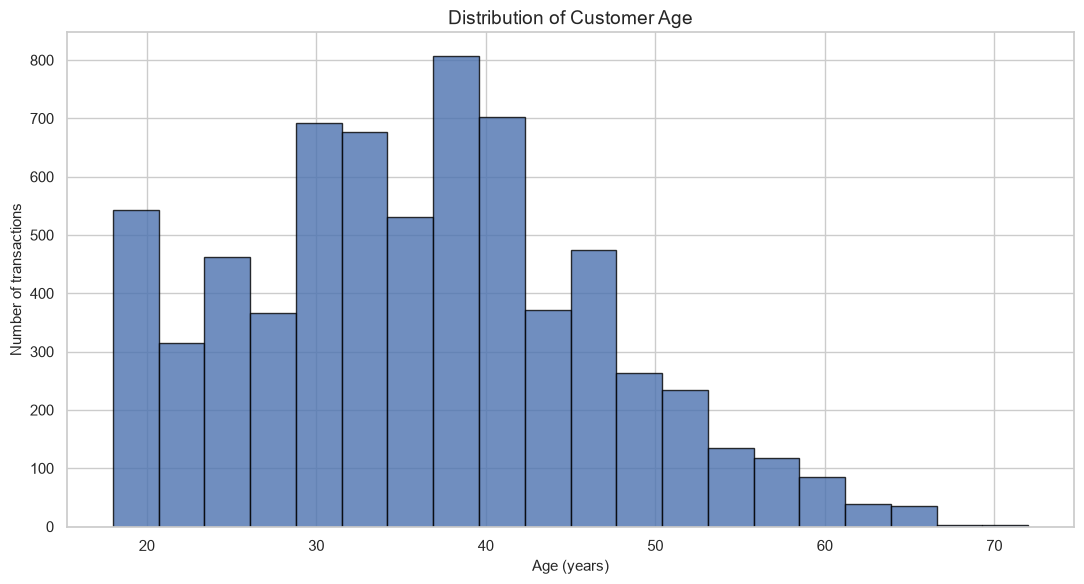

INSIGHT: Median customer age is 36.0 years. Skewness is 0.27; positive values indicate a right-skewed distribution, while negative values indicate a left-skewed distribution.


In [32]:
age_data = df["Age"].dropna()
fig, ax = plt.subplots()
ax.hist(age_data, bins=20, edgecolor="black", alpha=0.8)
ax.set(title="Distribution of Customer Age", xlabel="Age (years)", ylabel="Number of transactions")
plt.tight_layout()
plt.show()
print(f"INSIGHT: Median customer age is {age_data.median():.1f} years. "
      f"Skewness is {age_data.skew():.2f}; positive values indicate a right-skewed distribution, "
      "while negative values indicate a left-skewed distribution.")

## 10. Chart 5 — Annual customer income distribution

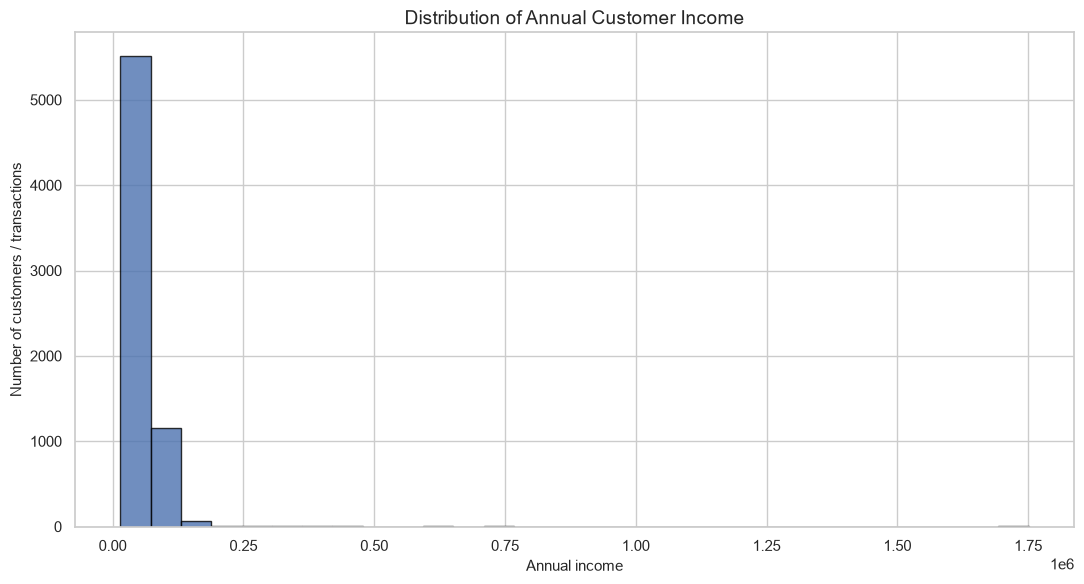

INSIGHT: Median income is 49,005.17; mean income is 55,101.38; skewness is 17.63. A mean well above the median and positive skewness suggest high-income outliers may pull the average upward.


In [14]:
income_data = df["Income"].dropna()
fig, ax = plt.subplots()
ax.hist(income_data, bins=30, edgecolor="black", alpha=0.8)
ax.set(title="Distribution of Annual Customer Income", xlabel="Annual income", ylabel="Number of customers / transactions")
plt.tight_layout()
plt.show()
print(f"INSIGHT: Median income is {income_data.median():,.2f}; mean income is {income_data.mean():,.2f}; "
      f"skewness is {income_data.skew():.2f}. A mean well above the median and positive skewness "
      "suggest high-income outliers may pull the average upward.")

## 11. Chart 6 — Sales spread by product category (box plot)

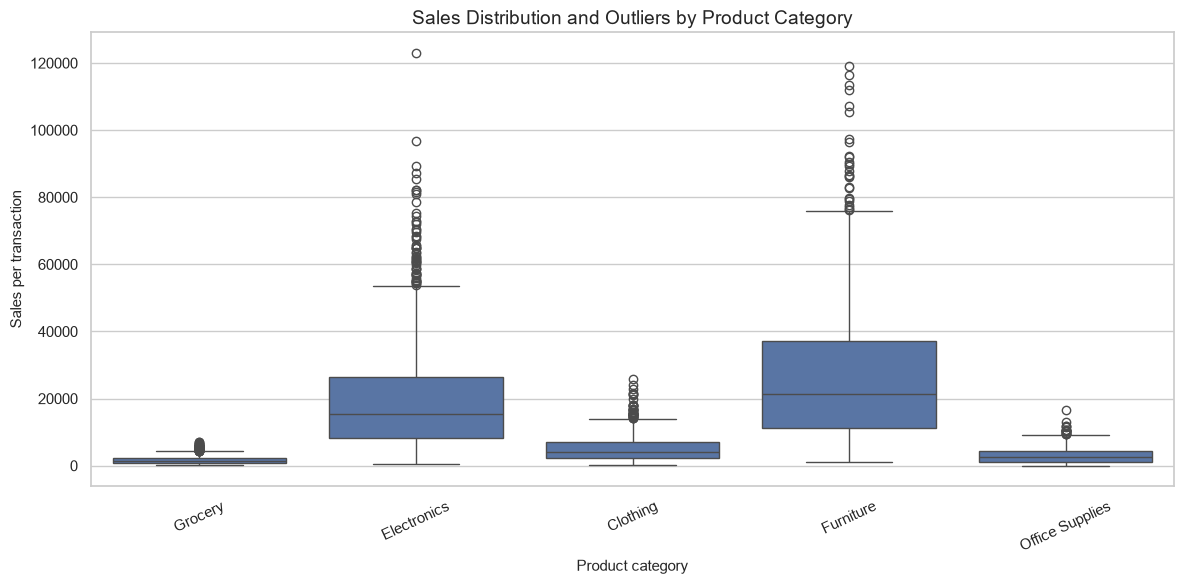

INSIGHT: Furniture has the highest median transaction sales (21,490.43). The boxes show the middle 50% of transactions; points beyond the whiskers indicate unusually small or large transactions.


In [33]:
box_data = df.dropna(subset=["Product_Category", "Sales"])
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=box_data, x="Product_Category", y="Sales", ax=ax)
ax.set(title="Sales Distribution and Outliers by Product Category",
       xlabel="Product category", ylabel="Sales per transaction")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
medians = box_data.groupby("Product_Category")["Sales"].median().sort_values(ascending=False)
print(f"INSIGHT: {medians.index[0]} has the highest median transaction sales "
      f"({medians.iloc[0]:,.2f}). The boxes show the middle 50% of transactions; points beyond "
      "the whiskers indicate unusually small or large transactions.")

## 12. Chart 7 — Sales vs Profit

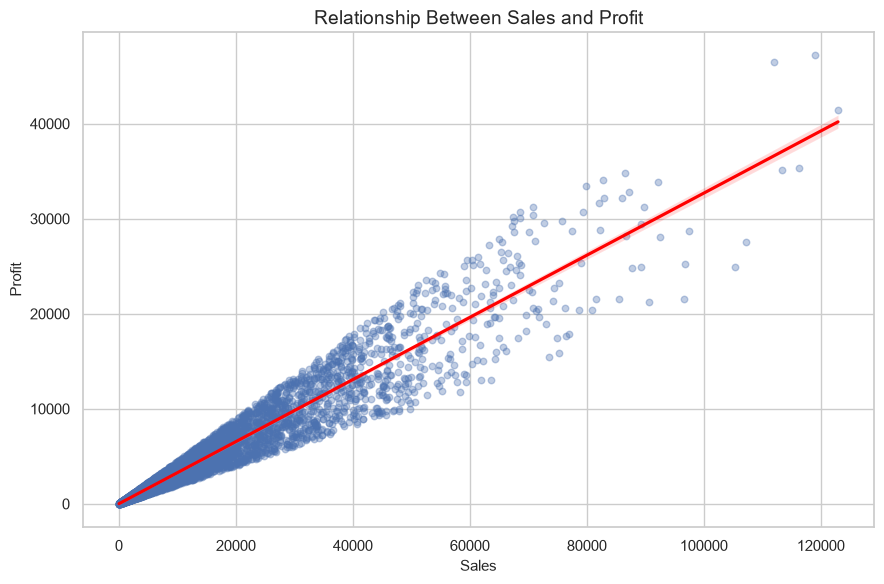

INSIGHT: Sales and Profit have a Pearson correlation of 0.97. A positive relationship means higher-sales transactions generally tend to generate higher profit, but the spread around the trend line shows that sales alone do not explain profitability.


In [34]:
scatter_data = df.dropna(subset=["Sales", "Profit"])
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(data=scatter_data, x="Sales", y="Profit",
            scatter_kws={"alpha": 0.35, "s": 22}, line_kws={"color": "red"}, ax=ax)
ax.set(title="Relationship Between Sales and Profit", xlabel="Sales", ylabel="Profit")
plt.tight_layout()
plt.show()
corr_sales_profit = scatter_data["Sales"].corr(scatter_data["Profit"])
print(f"INSIGHT: Sales and Profit have a Pearson correlation of {corr_sales_profit:.2f}. "
      "A positive relationship means higher-sales transactions generally tend to generate higher profit, "
      "but the spread around the trend line shows that sales alone do not explain profitability.")

## 13. Chart 8 — Discount vs Profit

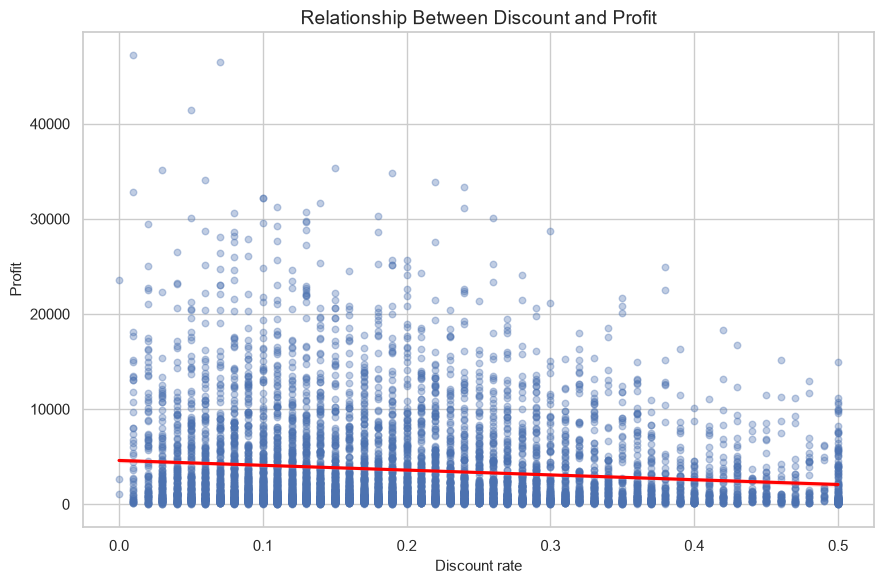

INSIGHT: Discount and Profit have a Pearson correlation of -0.12. A negative association suggests larger discounts may be linked with lower profit, so discount decisions should be evaluated against margin rather than sales volume alone.


In [35]:
discount_data = df.dropna(subset=["Discount", "Profit"])
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(data=discount_data, x="Discount", y="Profit",
            scatter_kws={"alpha": 0.35, "s": 22}, line_kws={"color": "red"}, ax=ax)
ax.set(title="Relationship Between Discount and Profit",
       xlabel="Discount rate", ylabel="Profit")
plt.tight_layout()
plt.show()
corr_discount_profit = discount_data["Discount"].corr(discount_data["Profit"])
print(f"INSIGHT: Discount and Profit have a Pearson correlation of {corr_discount_profit:.2f}. "
      "A negative association suggests larger discounts may be linked with lower profit, "
      "so discount decisions should be evaluated against margin rather than sales volume alone.")

## 14. Chart 9 — Sales share by customer segment (donut chart)

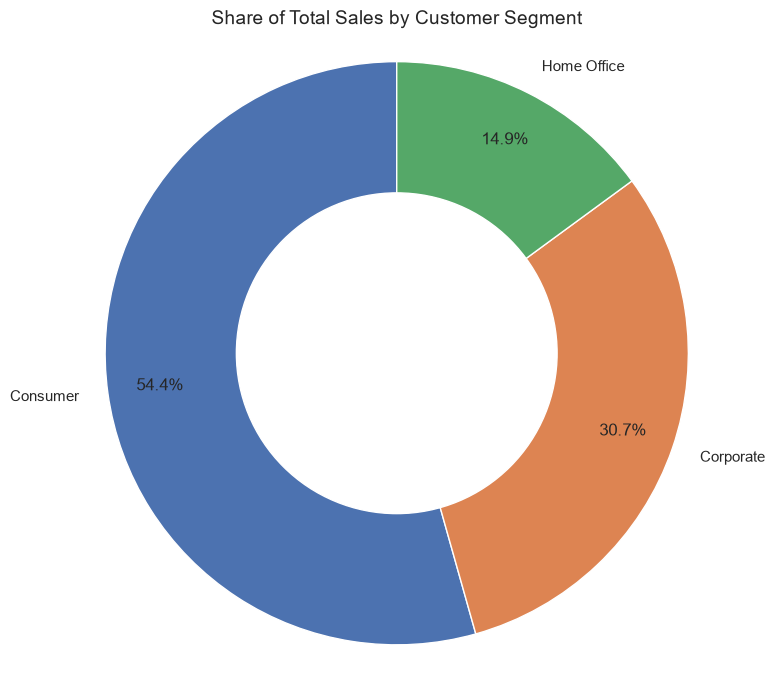

INSIGHT: Consumer contributes the largest sales share (54.4%). This indicates which customer segment currently contributes most to revenue.


In [37]:
segment_sales = df.groupby("Customer_Segment")["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
wedges, texts, autotexts = ax.pie(
    segment_sales, labels=segment_sales.index, autopct="%1.1f%%",
    startangle=90, pctdistance=0.82
)
centre = plt.Circle((0, 0), 0.55, fc="white")
ax.add_artist(centre)
ax.set_title("Share of Total Sales by Customer Segment")
ax.axis("equal")
plt.tight_layout()
plt.show()
print(f"INSIGHT: {segment_sales.index[0]} contributes the largest sales share "
      f"({segment_sales.iloc[0] / segment_sales.sum() * 100:.1f}%). "
      "This indicates which customer segment currently contributes most to revenue.")

## 15. Chart 10 — Correlation heatmap

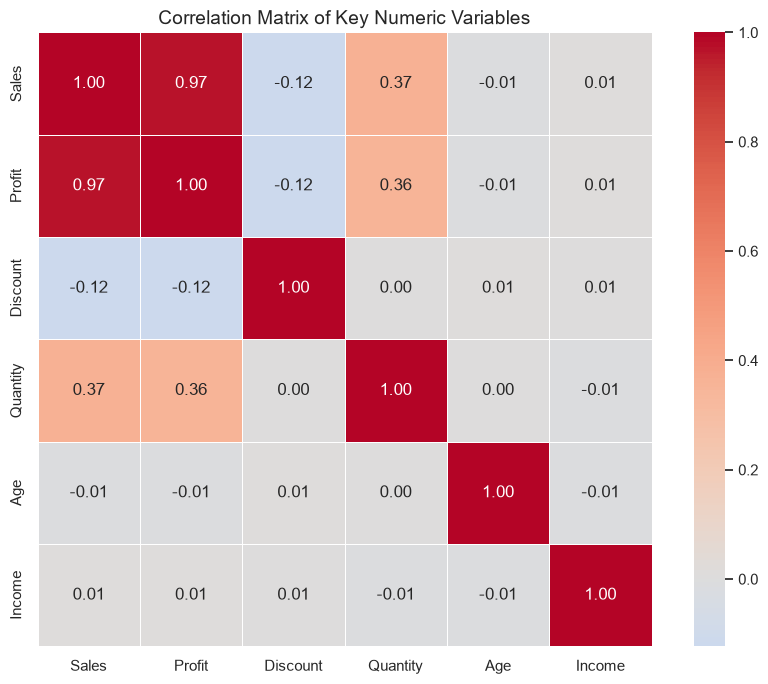

INSIGHT: Correlation values close to +1 indicate a strong positive linear association; values close to -1 indicate a strong negative association; values near 0 indicate a weak linear association. Correlation does not prove causation.


In [38]:
numeric_cols = ["Sales", "Profit", "Discount", "Quantity", "Age", "Income"]
corr = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix of Key Numeric Variables")
plt.tight_layout()
plt.show()
print("INSIGHT: Correlation values close to +1 indicate a strong positive linear association; "
      "values close to -1 indicate a strong negative association; values near 0 indicate a weak "
      "linear association. Correlation does not prove causation.")

## 16. Chart 11 — Average sales by category and region (pivot heatmap)

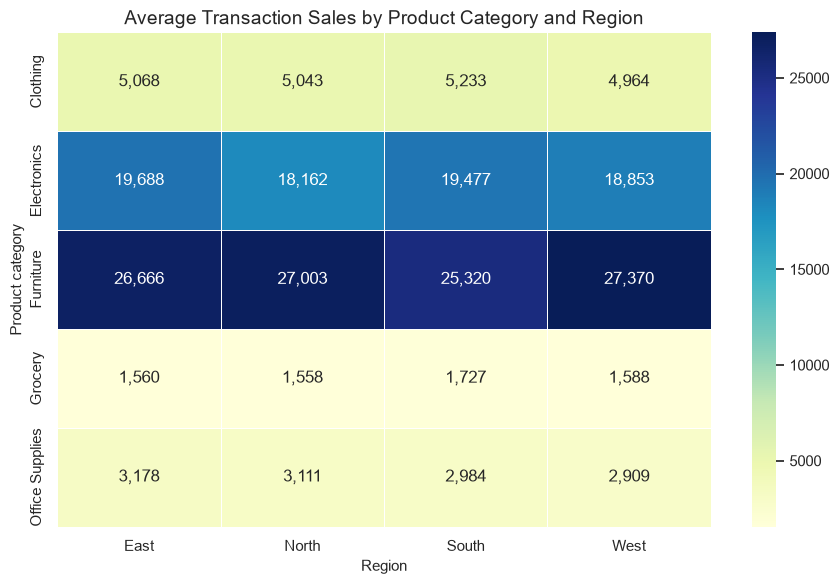

INSIGHT: Darker cells represent higher average transaction sales for that category-region pair. Use the matrix to identify where each category has stronger average order values.


In [39]:
pivot_sales = pd.pivot_table(
    df, values="Sales", index="Product_Category", columns="Region",
    aggfunc="mean"
)
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pivot_sales, annot=True, fmt=",.0f", cmap="YlGnBu",
            linewidths=0.5, ax=ax)
ax.set(title="Average Transaction Sales by Product Category and Region",
       xlabel="Region", ylabel="Product category")
plt.tight_layout()
plt.show()
print("INSIGHT: Darker cells represent higher average transaction sales for that category-region pair. "
      "Use the matrix to identify where each category has stronger average order values.")

## 17. Additional analysis — Satisfaction level

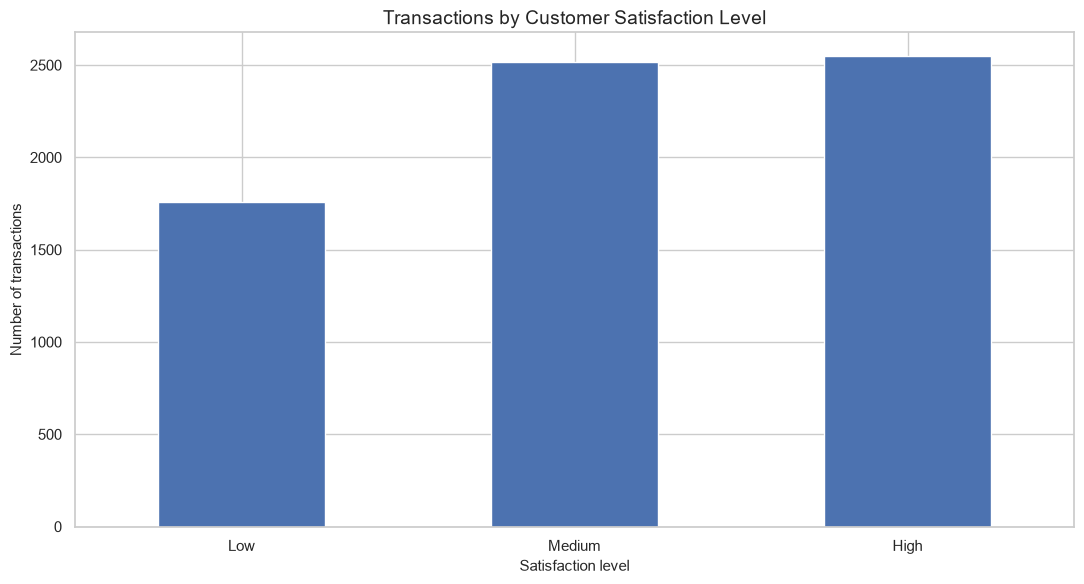

INSIGHT: Satisfaction distribution — Low: 1,758 (25.8%), Medium: 2,518 (36.9%), High: 2,549 (37.3%). Review low-satisfaction transactions to identify service or product issues.


In [40]:
satisfaction_order = [x for x in ["Low", "Medium", "High"] if x in df["Satisfaction_Level"].dropna().unique()]
satisfaction_counts = df["Satisfaction_Level"].value_counts().reindex(satisfaction_order)
fig, ax = plt.subplots()
satisfaction_counts.plot(kind="bar", ax=ax)
ax.set(title="Transactions by Customer Satisfaction Level",
       xlabel="Satisfaction level", ylabel="Number of transactions")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
valid_sat = df["Satisfaction_Level"].dropna()
if len(valid_sat):
    print("INSIGHT: Satisfaction distribution — " +
          ", ".join(f"{k}: {v:,} ({v/len(valid_sat)*100:.1f}%)" for k, v in satisfaction_counts.dropna().items()) +
          ". Review low-satisfaction transactions to identify service or product issues.")

## 18. Additional analysis — Return rate by product category

,Transactions,Returns,Return Rate %
Product_Category,,,
Clothing,1533,207,13.50
Furniture,979,129,13.18
Grocery,1669,208,12.46
Electronics,1975,239,12.10
Office Supplies,844,97,11.49


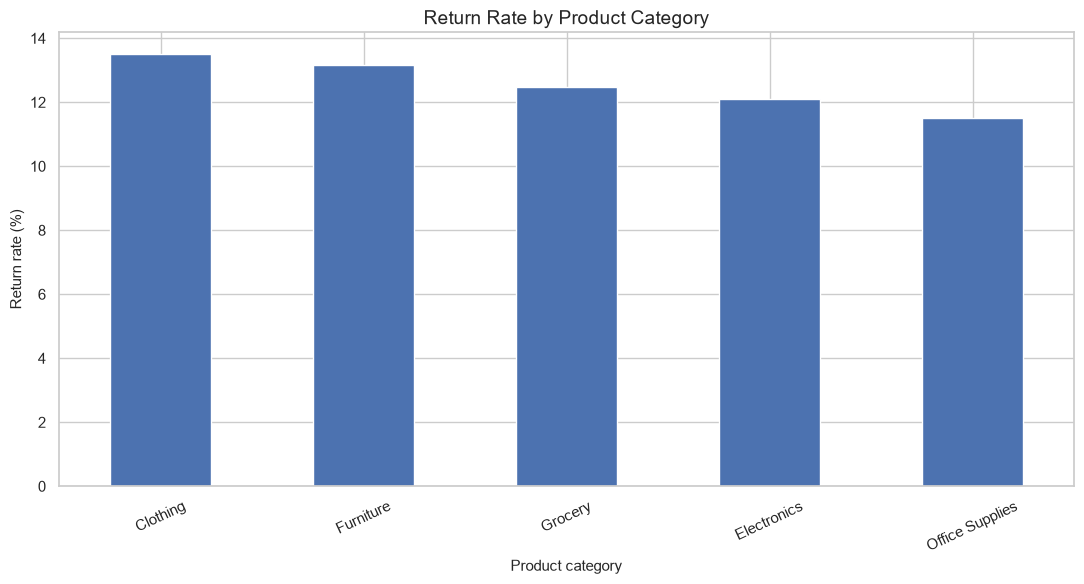

INSIGHT: Clothing has the highest observed return rate (13.5%). Investigate product quality, descriptions, packaging, and delivery experience in categories with higher return rates.


In [41]:
return_summary = (df.assign(Return_Flag=df["Returned"].astype(str).str.strip().str.lower().eq("yes"))
                    .groupby("Product_Category")
                    .agg(Transactions=("Transaction_ID", "count"),
                         Returns=("Return_Flag", "sum")))
return_summary["Return Rate %"] = return_summary["Returns"] / return_summary["Transactions"] * 100
return_summary = return_summary.sort_values("Return Rate %", ascending=False)
display(return_summary)

fig, ax = plt.subplots()
return_summary["Return Rate %"].plot(kind="bar", ax=ax)
ax.set(title="Return Rate by Product Category", xlabel="Product category", ylabel="Return rate (%)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
print(f"INSIGHT: {return_summary.index[0]} has the highest observed return rate "
      f"({return_summary.iloc[0]['Return Rate %']:.1f}%). Investigate product quality, descriptions, "
      "packaging, and delivery experience in categories with higher return rates.")

## 19. Additional analysis — Payment method and delivery mode

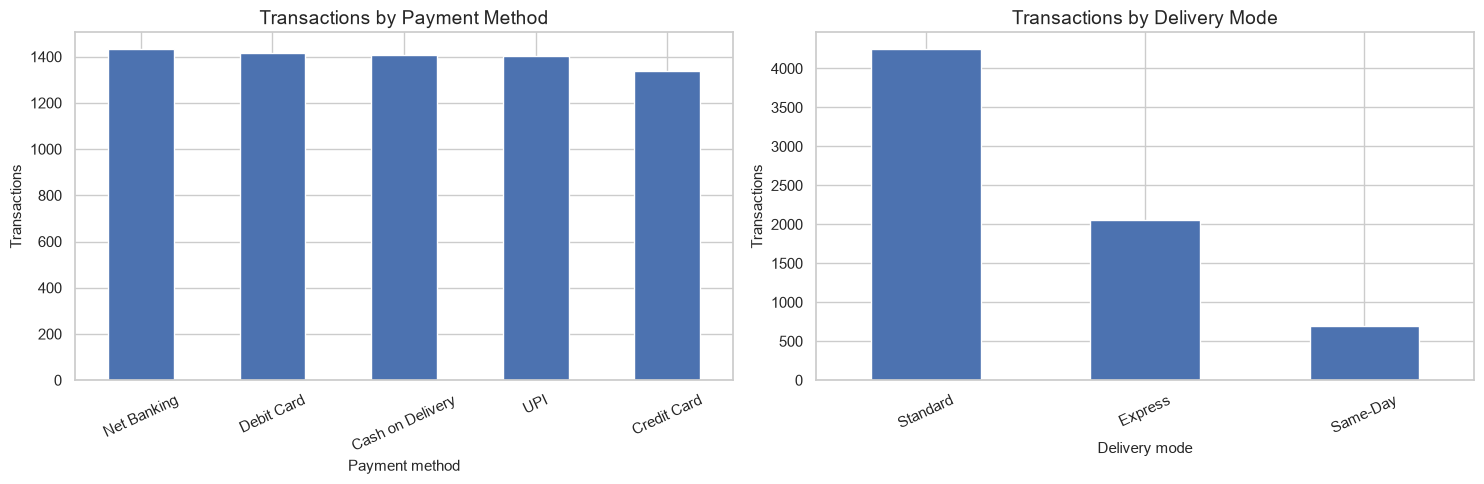

INSIGHT: These charts show how customers pay and how orders are delivered. Use the mix to plan payment support and delivery capacity; transaction count alone does not measure profitability or customer preference strength.


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df["Payment_Method"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set(title="Transactions by Payment Method", xlabel="Payment method", ylabel="Transactions")
axes[0].tick_params(axis="x", rotation=25)
df["Delivery_Mode"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set(title="Transactions by Delivery Mode", xlabel="Delivery mode", ylabel="Transactions")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
print("INSIGHT: These charts show how customers pay and how orders are delivered. "
      "Use the mix to plan payment support and delivery capacity; transaction count alone does not "
      "measure profitability or customer preference strength.")

## 20. Delivery performance

Average delivery time: 6.49 days
Median delivery time: 6 days


,Average Delivery Days
Delivery_Mode,
Standard,6.46
Express,6.52
Same-Day,6.59


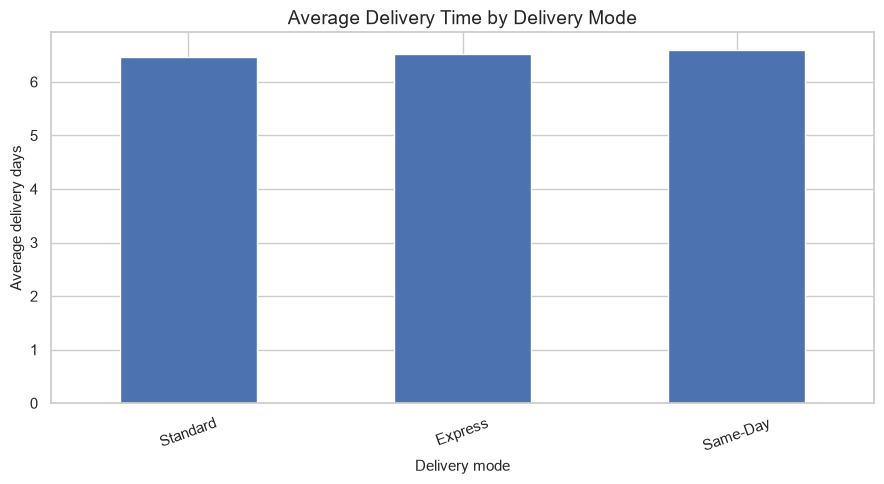

In [43]:
delivery = df.dropna(subset=["Order_Date", "Delivery_Date"]).copy()
delivery["Delivery_Days"] = (delivery["Delivery_Date"] - delivery["Order_Date"]).dt.days
delivery = delivery[delivery["Delivery_Days"] >= 0]
if len(delivery):
    print(f"Average delivery time: {delivery['Delivery_Days'].mean():.2f} days")
    print(f"Median delivery time: {delivery['Delivery_Days'].median():.0f} days")
    delivery_by_mode = delivery.groupby("Delivery_Mode")["Delivery_Days"].mean().sort_values()
    display(delivery_by_mode.to_frame("Average Delivery Days"))
    ax = delivery_by_mode.plot(kind="bar", figsize=(9, 5))
    ax.set(title="Average Delivery Time by Delivery Mode",
           xlabel="Delivery mode", ylabel="Average delivery days")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
else:
    print("No valid delivery-date pairs available for delivery-time analysis.")

## 21. Business findings and recommendations

In [44]:
# Data-driven summary tables
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)
category_profit = df.groupby("Product_Category")["Profit"].sum().sort_values(ascending=False)
segment_profit = df.groupby("Customer_Segment")["Profit"].sum().sort_values(ascending=False)

print("TOP REGION BY PROFIT:", region_profit.index[0], f"({region_profit.iloc[0]:,.2f})")
print("TOP CATEGORY BY PROFIT:", category_profit.index[0], f"({category_profit.iloc[0]:,.2f})")
print("TOP CUSTOMER SEGMENT BY PROFIT:", segment_profit.index[0], f"({segment_profit.iloc[0]:,.2f})")
print(f"OVERALL PROFIT MARGIN: {profit_margin:.2f}%")
print(f"OVERALL RETURN RATE: {(df['Returned'].astype(str).str.lower().eq('yes').mean()*100):.2f}%")

print("\nRECOMMENDATIONS")
print("1. Protect profitable categories and regions; compare profit as well as sales before allocating budget.")
print("2. Review discount levels where the discount-profit relationship is negative or weak.")
print("3. Investigate categories with the highest return rates to reduce avoidable returns.")
print("4. Track low customer satisfaction and connect it with category, region, and delivery mode.")
print("5. Use monthly sales patterns for inventory planning and seasonal campaigns.")
print("6. Treat extreme income and transaction values as review candidates, not automatic errors.")

TOP REGION BY PROFIT: East (6,607,664.00)
TOP CATEGORY BY PROFIT: Electronics (12,352,219.50)
TOP CUSTOMER SEGMENT BY PROFIT: Consumer (13,703,577.36)
OVERALL PROFIT MARGIN: 32.75%
OVERALL RETURN RATE: 12.57%

RECOMMENDATIONS
1. Protect profitable categories and regions; compare profit as well as sales before allocating budget.
2. Review discount levels where the discount-profit relationship is negative or weak.
3. Investigate categories with the highest return rates to reduce avoidable returns.
4. Track low customer satisfaction and connect it with category, region, and delivery mode.
5. Use monthly sales patterns for inventory planning and seasonal campaigns.
6. Treat extreme income and transaction values as review candidates, not automatic errors.


## 22. Final conclusion

This notebook converts the retail transaction data into a visual business story covering sales trends, regional and category performance, customer profiles, profitability, discounts, satisfaction, returns, and delivery. The charts should be interpreted together: high sales do not always mean high profit, and customer experience indicators such as satisfaction and returns should be considered alongside financial KPIs.

### Submission checklist
- [x] Cleaned dataset loaded
- [x] Data quality checks
- [x] KPI summary
- [x] Line, bar, histogram, box, scatter, donut, and heatmap chart types
- [x] More than 10 distinct visualizations
- [x] Insight captions / printed interpretations
- [x] Additional customer, return, payment, and delivery analysis
- [ ] Review the generated outputs and add your name, roll number, and course details before submission